# Walk-Rear Arena Visualization

Quick check that the translucent target box renders correctly in the WalkRear environment.

In [5]:
%load_ext autoreload
%autoreload 2
import os
import sys

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

if sys.platform == "darwin":
    os.environ["MUJOCO_GL"] = "glfw"
else:
    os.environ["MUJOCO_GL"] = "egl"

import jax
import mujoco
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format='retina'

from vnl_playground.tasks.rodent.walk_rear import WalkRear, default_config

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Create Environment

In [10]:
cfg = default_config()
print(f"Target position: ({cfg.target_x}, {cfg.target_y}, {cfg.target_z})")
print(f"XY tolerance: {cfg.xy_tolerance}, Z tolerance: {cfg.z_tolerance}")

cfg.target_z = 0.15

env = WalkRear(config=cfg)
print(f"\nModel compiled. Action size: {env.action_size}")
print(f"Observation size: {env.observation_size}")

Target position: (0.5, 0.0, 0.1)
XY tolerance: 0.05, Z tolerance: 0.02

Model compiled. Action size: 38
Observation size: 334


## Render Arena from Multiple Angles

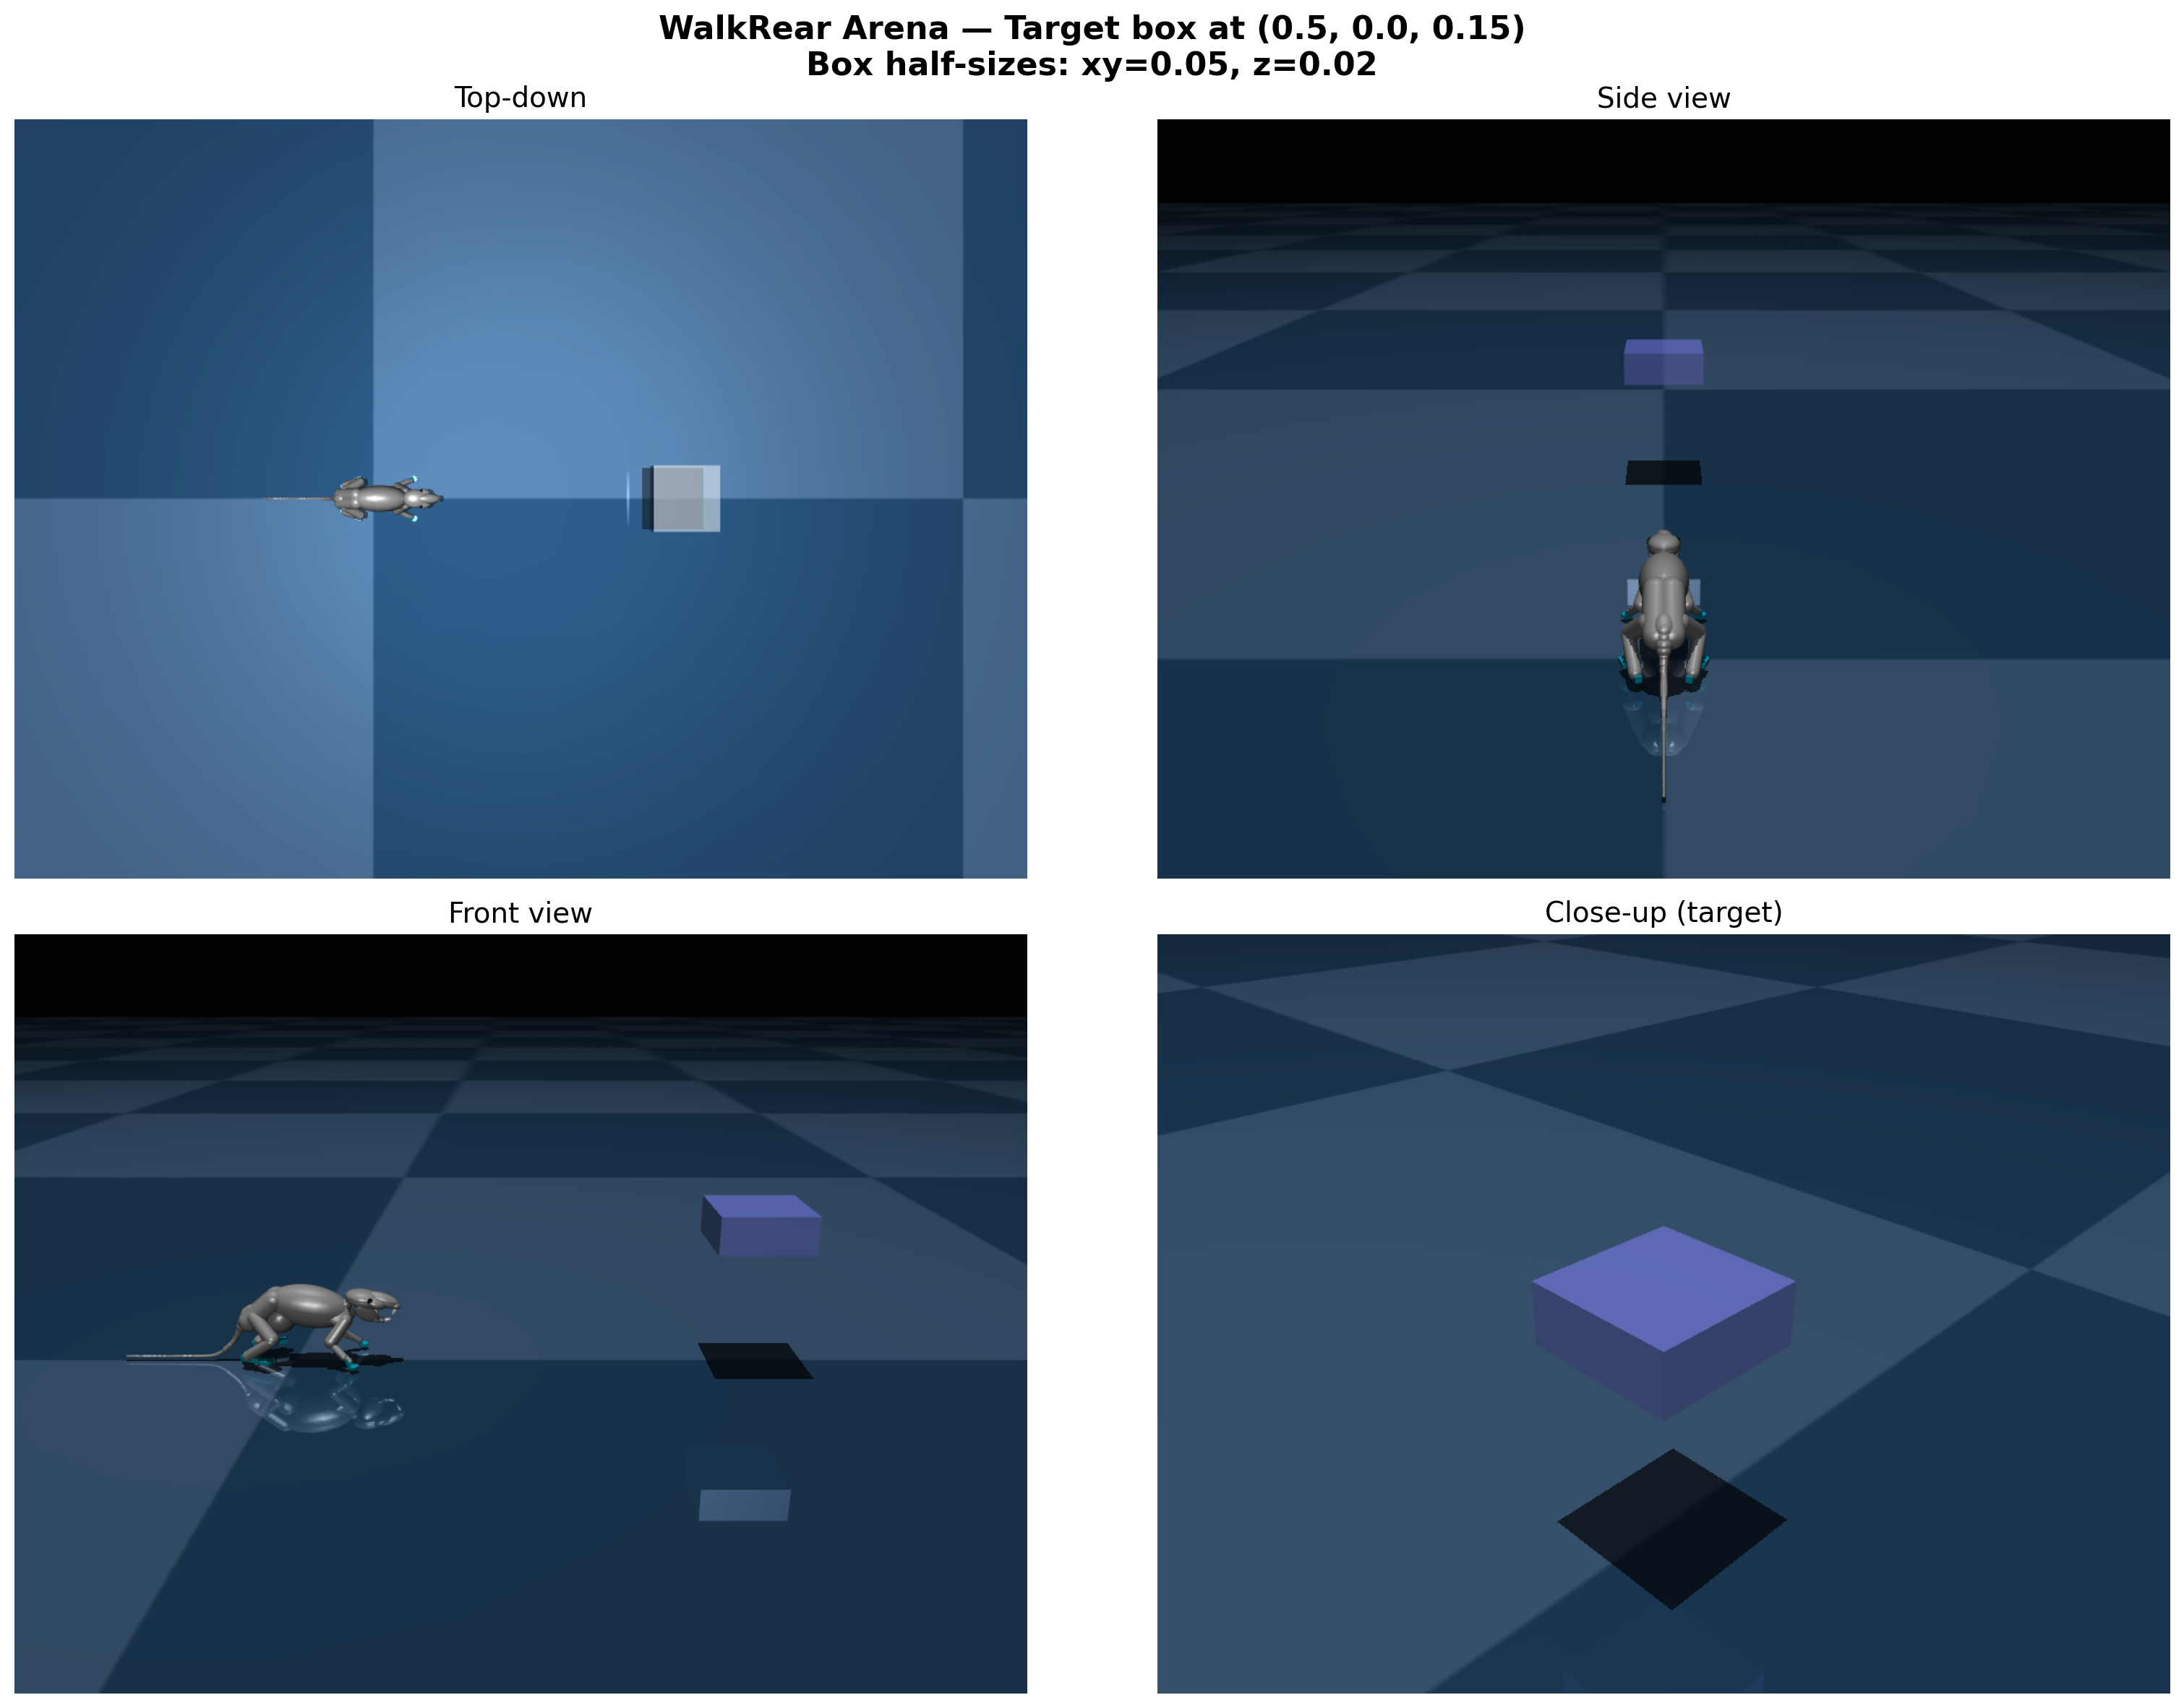

In [11]:
model = env.mj_model
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

renderer = mujoco.Renderer(model, height=720, width=960)

# Define camera views
cameras = {
    "Top-down": dict(azimuth=90, elevation=-90, distance=1.5, lookat=[0.25, 0.0, 0.05]),
    "Side view": dict(azimuth=0, elevation=-20, distance=1.0, lookat=[0.25, 0.0, 0.05]),
    "Front view": dict(azimuth=90, elevation=-20, distance=1.0, lookat=[0.25, 0.0, 0.05]),
    "Close-up (target)": dict(azimuth=45, elevation=-30, distance=0.5, lookat=[cfg.target_x, cfg.target_y, cfg.target_z]),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (name, cam_kwargs) in zip(axes.flat, cameras.items()):
    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_FREE
    cam.fixedcamid = -1
    cam.trackbodyid = -1
    cam.lookat[:] = cam_kwargs["lookat"]
    cam.distance = cam_kwargs["distance"]
    cam.azimuth = cam_kwargs["azimuth"]
    cam.elevation = cam_kwargs["elevation"]
    renderer.update_scene(data, camera=cam)
    frame = renderer.render()
    ax.imshow(frame)
    ax.set_title(name, fontsize=14)
    ax.axis("off")

plt.suptitle(
    f"WalkRear Arena — Target box at ({cfg.target_x}, {cfg.target_y}, {cfg.target_z})\n"
    f"Box half-sizes: xy={cfg.xy_tolerance}, z={cfg.z_tolerance}",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

renderer.close()

## Reset and Render with `env.render()`

Use the environment's built-in render method (same path as training rollout logging).

In [ ]:
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

rng = jax.random.PRNGKey(0)
state = jit_reset(rng)

print(f"Obs keys: {state.obs.keys()}")
print(f"Obs shapes: {jax.tree.map(lambda x: x.shape, state.obs)}")
print(f"hold_steps: {state.info['hold_steps']}")

In [ ]:
# Run a few steps with zero action to get the rodent settled
rollout_states = [state]
for _ in range(50):
    action = jax.numpy.zeros(env.action_size)
    state = jit_step(state, action)
    rollout_states.append(state)

# Render frames using env.render()
frames = env.render(
    rollout_states,
    camera="close_profile-rodent",
    height=480,
    width=640,
)

# Show first and last frame
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(frames[0])
axes[0].set_title("Frame 0 (after reset)", fontsize=13)
axes[0].axis("off")
axes[1].imshow(frames[-1])
axes[1].set_title(f"Frame {len(frames)-1} (after 50 zero-action steps)", fontsize=13)
axes[1].axis("off")
plt.suptitle("env.render() — target box should be visible", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()